In [1]:

import pandas as pd
import matplotlib.pyplot as plt

print("Construction Project Controls Analysis")
print("Pandas version:", pd.__version__)
print("Setup completed successfully.")


Construction Project Controls Analysis
Pandas version: 2.2.3
Setup completed successfully.


In [2]:

import pandas as pd

data = {
    "Item_ID": ["W001", "W002", "W003", "W004", "W005", "W006", "W007", "W008"],
    "Work_Item": [
        "Site Preparation",
        "Trench Excavation",
        "Pipe Supply & Installation",
        "Valve Chamber Construction",
        "Concrete Works",
        "Backfilling",
        "Testing & Commissioning",
        "Site Restoration"
    ],
    "BOQ_Quantity": [500, 1200, 3000, 12, 180, 950, 1, 500],
    "Unit_Rate": [120, 350, 850, 18500, 7200, 280, 85000, 180],
    "Actual_Quantity": [500, 1050, 2700, 10, 165, 900, 0, 350],
    "Actual_Expenditure": [58000, 375000, 2350000, 190000, 1210000, 255000, 0, 65000],
    "Planned_Progress": [1.00, 0.90, 0.95, 0.90, 0.85, 0.90, 0.50, 0.60]
}

df = pd.DataFrame(data)

df["BOQ_Amount"] = df["BOQ_Quantity"] * df["Unit_Rate"]
df["Earned_Value"] = df["Actual_Quantity"] * df["Unit_Rate"]
df["Progress"] = df["Actual_Quantity"] / df["BOQ_Quantity"]
df["Planned_Value"] = df["BOQ_Amount"] * df["Planned_Progress"]

display(df)


,Item_ID,Work_Item,BOQ_Quantity,Unit_Rate,Actual_Quantity,Actual_Expenditure,Planned_Progress,BOQ_Amount,Earned_Value,Progress,Planned_Value
0,W001,Site Preparation,500,120,500,58000,1.00,60000,60000,1.000000,60000.0
1,W002,Trench Excavation,1200,350,1050,375000,0.90,420000,367500,0.875000,378000.0
2,W003,Pipe Supply & Installation,3000,850,2700,2350000,0.95,2550000,2295000,0.900000,2422500.0
3,W004,Valve Chamber Construction,12,18500,10,190000,0.90,222000,185000,0.833333,199800.0
4,W005,Concrete Works,180,7200,165,1210000,0.85,1296000,1188000,0.916667,1101600.0
5,W006,Backfilling,950,280,900,255000,0.90,266000,252000,0.947368,239400.0
6,W007,Testing & Commissioning,1,85000,0,0,0.50,85000,0,0.000000,42500.0
7,W008,Site Restoration,500,180,350,65000,0.60,90000,63000,0.700000,54000.0


In [3]:

df = df.set_index("Item_ID")

display(df)


,Work_Item,BOQ_Quantity,Unit_Rate,Actual_Quantity,Actual_Expenditure,Planned_Progress,BOQ_Amount,Earned_Value,Progress,Planned_Value
Item_ID,,,,,,,,,,
W001,Site Preparation,500,120,500,58000,1.00,60000,60000,1.000000,60000.0
W002,Trench Excavation,1200,350,1050,375000,0.90,420000,367500,0.875000,378000.0
W003,Pipe Supply & Installation,3000,850,2700,2350000,0.95,2550000,2295000,0.900000,2422500.0
W004,Valve Chamber Construction,12,18500,10,190000,0.90,222000,185000,0.833333,199800.0
W005,Concrete Works,180,7200,165,1210000,0.85,1296000,1188000,0.916667,1101600.0
W006,Backfilling,950,280,900,255000,0.90,266000,252000,0.947368,239400.0
W007,Testing & Commissioning,1,85000,0,0,0.50,85000,0,0.000000,42500.0
W008,Site Restoration,500,180,350,65000,0.60,90000,63000,0.700000,54000.0


In [4]:

# Calculate project-level KPIs

total_boq = df["BOQ_Amount"].sum()
earned_value = df["Earned_Value"].sum()
actual_expenditure = df["Actual_Expenditure"].sum()
planned_value = df["Planned_Value"].sum()

overall_progress = earned_value / total_boq
cpi = earned_value / actual_expenditure
spi = earned_value / planned_value
eac = total_boq / cpi
vac = total_boq - eac

# Display the results
kpis = pd.DataFrame({
    "KPI": [
        "Total BOQ Value",
        "Earned Value (EV)",
        "Actual Expenditure (AC)",
        "Total Planned Value (PV)",
        "Overall Progress",
        "Cost Performance Index (CPI)",
        "Schedule Performance Index (SPI)",
        "Estimate at Completion (EAC)",
        "Variance at Completion (VAC)"
    ],
    "Value": [
        total_boq,
        earned_value,
        actual_expenditure,
        planned_value,
        overall_progress,
        cpi,
        spi,
        eac,
        vac
    ]
})

display(kpis)


,KPI,Value
0,Total BOQ Value,4.989000e+06
1,Earned Value (EV),4.410500e+06
2,Actual Expenditure (AC),4.503000e+06
3,Total Planned Value (PV),4.497800e+06
4,Overall Progress,8.840449e-01
5,Cost Performance Index (CPI),9.794581e-01
6,Schedule Performance Index (SPI),9.805905e-01
7,Estimate at Completion (EAC),5.093633e+06
8,Variance at Completion (VAC),-1.046327e+05


In [5]:

# Create a readable copy of the KPI report
kpis_formatted = kpis.copy()

kpis_formatted["Value"] = kpis_formatted.apply(
    lambda row: (
        f"{row['Value']:.2%}"
        if row["KPI"] == "Overall Progress"
        else f"{row['Value']:,.2f}"
    ),
    axis=1
)

display(kpis_formatted)


,KPI,Value
0,Total BOQ Value,"4,989,000.00"
1,Earned Value (EV),"4,410,500.00"
2,Actual Expenditure (AC),"4,503,000.00"
3,Total Planned Value (PV),"4,497,800.00"
4,Overall Progress,88.40%
5,Cost Performance Index (CPI),0.98
6,Schedule Performance Index (SPI),0.98
7,Estimate at Completion (EAC),"5,093,632.69"
8,Variance at Completion (VAC),"-104,632.69"


In [6]:

# Calculate cost variance for each work item
df["Cost_Variance"] = df["Earned_Value"] - df["Actual_Expenditure"]

# Calculate cost variance as a percentage of BOQ value
df["Cost_Variance_Percent"] = (
    df["Cost_Variance"] / df["BOQ_Amount"]
) * 100

# Sort from largest cost overrun to most favorable variance
cost_analysis = df.sort_values("Cost_Variance")

# Display the work items with the largest overruns first
display(
    cost_analysis[
        [
            "Work_Item",
            "BOQ_Amount",
            "Earned_Value",
            "Actual_Expenditure",
            "Cost_Variance",
            "Cost_Variance_Percent"
        ]
    ].round(2)
)


,Work_Item,BOQ_Amount,Earned_Value,Actual_Expenditure,Cost_Variance,Cost_Variance_Percent
Item_ID,,,,,,
W003,Pipe Supply & Installation,2550000,2295000,2350000,-55000,-2.16
W005,Concrete Works,1296000,1188000,1210000,-22000,-1.70
W002,Trench Excavation,420000,367500,375000,-7500,-1.79
W004,Valve Chamber Construction,222000,185000,190000,-5000,-2.25
W006,Backfilling,266000,252000,255000,-3000,-1.13
W008,Site Restoration,90000,63000,65000,-2000,-2.22
W007,Testing & Commissioning,85000,0,0,0,0.00
W001,Site Preparation,60000,60000,58000,2000,3.33


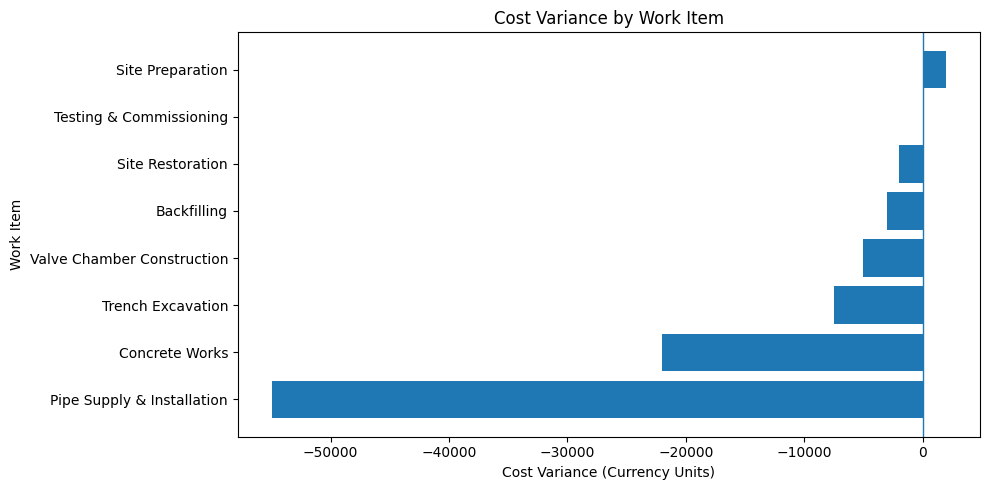

In [7]:

import matplotlib.pyplot as plt

# Sort work items by cost variance
chart_data = cost_analysis.sort_values("Cost_Variance")

# Create the chart
plt.figure(figsize=(10, 5))
plt.barh(
    chart_data["Work_Item"],
    chart_data["Cost_Variance"]
)

plt.axvline(0, linewidth=1)
plt.title("Cost Variance by Work Item")
plt.xlabel("Cost Variance (Currency Units)")
plt.ylabel("Work Item")
plt.tight_layout()
plt.show()


In [8]:

# Save the work-item cost analysis as a CSV file
cost_analysis.to_csv(
    "construction_cost_analysis.csv",
    index=True
)

print("Cost analysis saved successfully.")


Cost analysis saved successfully.
